# Неделя 03. pandas: от двух файлов к проверенному отчёту

        **Кейс:** интернет-магазин просит отчёт по завершённым заказам и городам.
        CSV содержит заказы, JSON — клиентов. В поставке намеренно есть два точных дубля
        и неизвестный клиент. Сначала проверяем данные, затем считаем деньги.

        **Результат:** воспроизводимая загрузка, фильтрация, `groupby`, безопасный `merge`,
        проверка потерь строк и один компактный аналитический отчёт. Все данные синтетические.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import json
from tempfile import TemporaryDirectory

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                     "grid.alpha": 0.2, "figure.dpi": 100})

def locate_week():
    "Работает из practice/, homework/, папки недели и корня репозитория."
    current = Path.cwd().resolve()
    for parent in (current, *current.parents):
        for candidate in (parent, parent / 'week_03_pandas_files'):
            if candidate.name == 'week_03_pandas_files' and (candidate / "datasets").is_dir():
                return candidate
    raise FileNotFoundError("Откройте notebook внутри полного клона репозитория.")

WEEK_DIR = locate_week()
DATA_DIR = WEEK_DIR / "datasets"
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)
print("Рабочая неделя:", WEEK_DIR.name)


Python: 3.12.14 | NumPy: 2.5.4 | pandas: 3.0.6
Рабочая неделя: week_03_pandas_files


## 1. Читаем CSV и JSON с явным смыслом типов

        pandas DataFrame — таблица с именами столбцов и индексом строк. Дата не должна оставаться
        произвольной строкой, если нужны календарные вычисления. Идентификатор — ключ,
        даже если хранится целым числом. `shipping_days` имеет пропуски по смыслу процесса.


In [2]:
raw_orders = pd.read_csv(DATA_DIR / "orders.csv", parse_dates=["ordered_at"])
with (DATA_DIR / "customers.json").open(encoding="utf-8") as handle:
    customers = pd.DataFrame(json.load(handle))
display(raw_orders.head())
display(customers.head())
print("Orders:", raw_orders.shape, "| Customers:", customers.shape)


,order_id,customer_id,ordered_at,product,unit_price_kzt,quantity,status,shipping_days
0,1001,13,2026-02-01,keyboard,14000,2,cancelled,NaN
1,1002,33,2026-02-01,webcam,23000,2,completed,5.0
2,1003,5,2026-02-01,mouse,6500,1,completed,4.0
3,1004,34,2026-02-01,webcam,23000,4,completed,6.0
4,1005,22,2026-02-01,headset,18000,1,completed,4.0


,customer_id,city,segment
0,1,Atyrau,individual
1,2,Aktau,individual
2,3,Atyrau,small_business
3,4,Aktau,small_business
4,5,Atyrau,small_business


Orders: (182, 8) | Customers: (40, 3)


## 2. Профиль качества до изменений

        `duplicated()` сравнивает все столбцы, а `duplicated('order_id')` — только ключ.
        Это разные вопросы: одинаковый ID с разным количеством нельзя молча удалить как точную копию.
        В нашем CSV повторы полные; сохраняем исходный DataFrame для аудита.


In [3]:
quality = pd.DataFrame({"dtype": raw_orders.dtypes.astype(str),
                        "missing": raw_orders.isna().sum(), "nunique": raw_orders.nunique()})
display(quality)
print("Точных дублей:", raw_orders.duplicated().sum())
display(raw_orders.loc[raw_orders.duplicated("order_id", keep=False)].sort_values("order_id"))
orders = raw_orders.drop_duplicates().copy()
assert len(raw_orders) == 182 and len(orders) == 180
assert orders["order_id"].is_unique and customers["customer_id"].is_unique


,dtype,missing,nunique
order_id,int64,0,180
customer_id,int64,0,39
ordered_at,datetime64[us],0,30
product,str,0,4
unit_price_kzt,int64,0,4
quantity,int64,0,4
status,str,0,3
shipping_days,float64,34,7


Точных дублей: 2


,order_id,customer_id,ordered_at,product,unit_price_kzt,quantity,status,shipping_days
11,1012,36,2026-02-02,headset,18000,3,completed,3.0
180,1012,36,2026-02-02,headset,18000,3,completed,3.0
75,1076,17,2026-02-13,mouse,6500,2,completed,5.0
181,1076,17,2026-02-13,mouse,6500,2,completed,5.0


## 3. Индекс, loc и iloc

        `iloc` выбирает по позиции, `loc` — по меткам или логической маске.
        Индекс удобен для поиска, но не заменяет проверку уникальности бизнес-ключа.
        При назначении используем `.loc` или `.assign`, без цепочек вида `df[mask][column] = ...`.


In [4]:
indexed = orders.set_index("order_id", verify_integrity=True)
display(indexed.loc[[1001, 1002], ["product", "quantity", "status"]])
display(indexed.iloc[:3, :4])
selected = orders.loc[(orders["quantity"] >= 3) & (orders["status"] == "completed"),
                      ["order_id", "product", "quantity"]]
display(selected.head())
assert selected["quantity"].ge(3).all()


/tmp/ipykernel_5109/3658456797.py:1: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  indexed = orders.set_index("order_id", verify_integrity=True)


,product,quantity,status
order_id,,,
1001,keyboard,2,cancelled
1002,webcam,2,completed


,customer_id,ordered_at,product,unit_price_kzt
order_id,,,,
1001,13,2026-02-01,keyboard,14000
1002,33,2026-02-01,webcam,23000
1003,5,2026-02-01,mouse,6500


,order_id,product,quantity
3,1004,webcam,4
5,1006,webcam,3
7,1008,webcam,3
8,1009,mouse,3
9,1010,headset,3


## 4. Производные величины и границы метрики

        Для заказа $i$: $v_i=q_i p_i$ (количество × цена).
        **Выручкой этого упражнения** считаем сумму $v_i$ только завершённых заказов.
        Для остальных строк выручка равна 0 по нашему определению, но shipping_days остаётся неизвестной.
        Это иллюстрирует, почему разные столбцы требуют разных правил обработки пропусков.


In [5]:
orders = orders.assign(order_value_kzt=orders["quantity"] * orders["unit_price_kzt"])
orders["revenue_kzt"] = orders["order_value_kzt"].where(orders["status"].eq("completed"), 0)
orders["weekday"] = orders["ordered_at"].dt.dayofweek  # 0 = понедельник
assert orders["quantity"].gt(0).all() and orders["unit_price_kzt"].ge(0).all()
assert orders.loc[orders["status"].ne("completed"), "revenue_kzt"].eq(0).all()
display(orders[["order_id", "status", "order_value_kzt", "revenue_kzt", "shipping_days"]].head(8))


,order_id,status,order_value_kzt,revenue_kzt,shipping_days
0,1001,cancelled,28000,0,NaN
1,1002,completed,46000,46000,5.0
2,1003,completed,6500,6500,4.0
3,1004,completed,92000,92000,6.0
4,1005,completed,18000,18000,4.0
5,1006,completed,69000,69000,4.0
6,1007,completed,46000,46000,3.0
7,1008,completed,69000,69000,6.0


## 5. Группируем с именованными агрегатами

        `size` считает строки группы, а `count` — непустые значения выбранного столбца.
        Для длительности доставки явно показываем число доступных измерений.
        Средний чек ниже относится только к завершённым заказам, а не ко всем созданным.


In [6]:
completed = orders.loc[orders["status"].eq("completed")].copy()
by_product = completed.groupby("product").agg(
    completed_orders=("order_id", "size"), units=("quantity", "sum"),
    revenue_kzt=("revenue_kzt", "sum"), mean_order_kzt=("revenue_kzt", "mean"),
    shipping_observations=("shipping_days", "count"), median_shipping=("shipping_days", "median"))
display(by_product.round(2))
assert by_product["revenue_kzt"].sum() == completed["revenue_kzt"].sum()
display(orders.groupby("status").agg(rows=("order_id", "size"), known_shipping=("shipping_days", "count")))


,completed_orders,units,revenue_kzt,mean_order_kzt,shipping_observations,median_shipping
product,,,,,,
headset,34,81,1458000,42882.35,34,4.0
keyboard,26,69,966000,37153.85,26,4.5
mouse,42,106,689000,16404.76,42,4.0
webcam,44,105,2415000,54886.36,44,4.0


,rows,known_shipping
status,,
cancelled,14,0
completed,146,146
processing,20,0


## 6. Объединение many-to-one: одна строка заказа — один клиент

        `validate='many_to_one'` требует уникальность ключа справа.
        `indicator=True` показывает, какие строки не нашли пару.
        LEFT JOIN сохраняет все заказы, поэтому неизвестного клиента можно заметить и разобрать.
        INNER JOIN удалил бы его молча, если не сравнить число строк и сумму выручки.


In [7]:
merged = orders.merge(customers, on="customer_id", how="left",
                      validate="many_to_one", indicator=True)
assert len(merged) == len(orders)
assert merged["revenue_kzt"].sum() == orders["revenue_kzt"].sum()
unmatched = merged.loc[merged["_merge"].eq("left_only"), ["order_id", "customer_id", "revenue_kzt"]]
display(unmatched)
assert unmatched["customer_id"].tolist() == [999]
merged["city_report"] = merged["city"].fillna("UNKNOWN")


,order_id,customer_id,revenue_kzt
37,1038,999,92000


## 7. Проверка защищает от размножения строк

        Если в справочнике две записи одного клиента, один заказ при join может превратиться в две строки.
        Покажем ошибку на отдельной испорченной копии, не меняя исходный справочник.
        `try/except` здесь нужен, чтобы учебный notebook продолжился после ожидаемой ошибки контракта.


In [8]:
bad_customers = pd.concat([customers, customers.iloc[[0]]], ignore_index=True)
blocked = False
try:
    orders.merge(bad_customers, on="customer_id", how="left", validate="many_to_one")
except pd.errors.MergeError as exc:
    blocked = True
    print("Ожидаемая защита:", type(exc).__name__)
assert blocked, "Дублирование ключа справочника должно блокироваться"
assert customers["customer_id"].is_unique


Ожидаемая защита: MergeError


## 8. Описательная аналитика после join

        Отчёт должен сохранить неизвестные значения отдельной группой.
        Для каждого города показываем число заказов, завершённые заказы и выручку.
        Доля завершений имеет знаменатель «все созданные заказы города», а средний чек —
        «только завершённые заказы». Эти знаменатели нельзя подменять друг другом.


In [9]:
merged["is_completed"] = merged["status"].eq("completed")
by_city = merged.groupby("city_report").agg(
    all_orders=("order_id", "size"), completed_orders=("is_completed", "sum"),
    completion_rate=("is_completed", "mean"), revenue_kzt=("revenue_kzt", "sum"))
by_city["mean_completed_order_kzt"] = by_city["revenue_kzt"].div(by_city["completed_orders"].replace(0, np.nan))
display(by_city.round(2))
assert by_city["all_orders"].sum() == len(orders)
assert by_city["revenue_kzt"].sum() == completed["revenue_kzt"].sum()


,all_orders,completed_orders,completion_rate,revenue_kzt,mean_completed_order_kzt
city_report,,,,,
Aktau,67,55,0.82,1933500,35154.55
Astana,45,36,0.80,1362500,37847.22
Atyrau,67,54,0.81,2140000,39629.63
UNKNOWN,1,1,1.00,92000,92000.00


## 9. Сводная таблица и временная агрегация

        `pivot_table` строит двумерную сводку. `resample` агрегирует даты по календарной частоте.
        Нулевую выручку в дне без завершённых заказов здесь можно указать явно,
        поскольку файл покрывает весь заданный период. Для неполной выгрузки ноль мог бы вводить в заблуждение.


In [10]:
city_product = merged.pivot_table(index="city_report", columns="product", values="revenue_kzt",
                                  aggfunc="sum", fill_value=0)
daily = orders.set_index("ordered_at")["revenue_kzt"].resample("D").sum()
display(city_product)
assert city_product.to_numpy().sum() == orders["revenue_kzt"].sum()
assert daily.sum() == orders["revenue_kzt"].sum()


product,headset,keyboard,mouse,webcam
city_report,,,,
Aktau,684000,434000,240500,575000
Astana,252000,252000,214500,644000
Atyrau,522000,280000,234000,1104000
UNKNOWN,0,0,0,92000


## 10. Графики: значение, единица и подпись ограничения

        Сравнение выручки не является рейтингом эффективности: группы могут отличаться размером.
        Поэтому рядом с денежным показателем в отчёте оставляем число заказов.
        Линия по дням — описание 30 синтетических дней, не оценка сезонности.


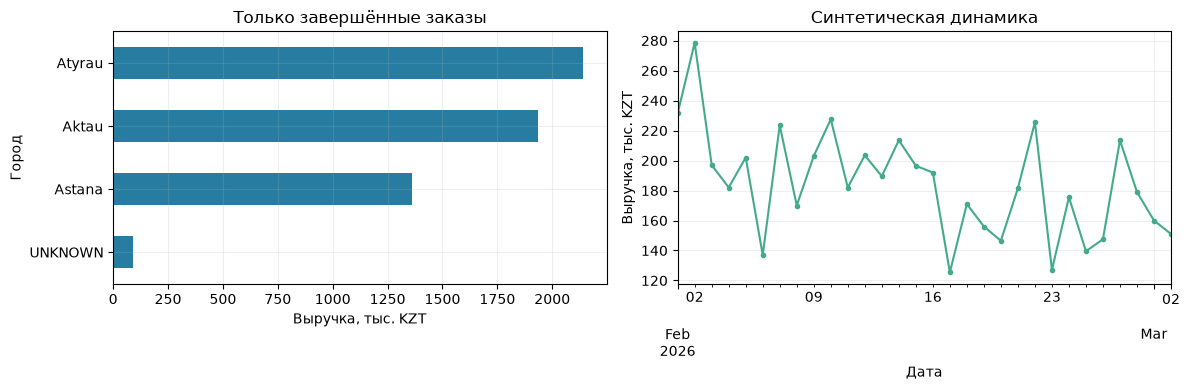

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
(by_city["revenue_kzt"].sort_values() / 1000).plot.barh(ax=axes[0], color="#277DA1")
axes[0].set(xlabel="Выручка, тыс. KZT", ylabel="Город", title="Только завершённые заказы")
(daily / 1000).plot(ax=axes[1], color="#43AA8B", marker=".")
axes[1].set(xlabel="Дата", ylabel="Выручка, тыс. KZT", title="Синтетическая динамика")
plt.tight_layout()
plt.show()


## 11. Экспорт и round-trip проверка

        CSV не хранит все типы pandas, поэтому после повторного чтения проверяем значения и ключи.
        Используем временную папку, чтобы лабораторная не перезаписывала исходные данные.
        Такой тест ловит случайное сохранение индекса как лишнего столбца или потерю строк.


In [12]:
export = by_city.reset_index()
with TemporaryDirectory() as temp_dir:
    report_path = Path(temp_dir) / "city_report.csv"
    export.to_csv(report_path, index=False, encoding="utf-8")
    restored = pd.read_csv(report_path)
assert restored.columns.tolist() == export.columns.tolist()
assert restored["city_report"].tolist() == export["city_report"].tolist()
assert np.allclose(restored["revenue_kzt"], export["revenue_kzt"])
print("CSV round-trip: структура, ключи и выручка сохранены.")


CSV round-trip: структура, ключи и выручка сохранены.


## Что должно попасть в финальный вывод

        1. Сколько исходных строк было, сколько точных дублей удалено и почему.
        2. Сколько заказов не нашли клиента и как они отражены в отчёте.
        3. Что в этом упражнении означает «выручка» и какие бизнес-процессы отсутствуют.
        4. Какие суммы независимо сошлись после группировки и join.

        Переходите к [Homework Week 03](../homework/Homework_Week_03.md).


## Документация и дальнейшее чтение

- [pandas: вводные учебники](https://pandas.pydata.org/docs/getting_started/intro_tutorials/index.html)
- [pandas: GroupBy](https://pandas.pydata.org/docs/user_guide/groupby.html)
- [pandas: merge и join](https://pandas.pydata.org/docs/user_guide/merging.html)

Код, объяснения и синтетические примеры в этой лабораторной подготовлены для курса; это не копия университетского ноутбука. Дополнительные лекции находятся в `../presentations/`. Документация проверена 18 октября 2026 года; версии среды закреплены на уровне репозитория.
